# Task 5: Fixed-price contracts, rising costs and how work is won

Pranav Mahadoo

Contractors that agree their price before they know their costs carry every cost rise themselves. This notebook looks at how much that matters, using 15 years of filings from Granite Construction, a US contractor that reports exactly this risk, and the official construction cost index for Mauritius. The two scripts in this folder, `escalation_check.py` and `kdm_touchpoints.py`, come out of what it finds. The last section explains why there are two.

In [1]:
import json
import re
import sys
import tempfile
import time
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup

here = Path.cwd()
HERE = next(p for p in [here, *here.parents, *here.glob('*'), *here.glob('*/*')] if (p / 'escalation_check.py').is_file())
sys.dont_write_bytecode = True
sys.path.insert(0, str(HERE))
DATA = HERE / 'data'
CACHE = Path(tempfile.gettempdir()) / 'granite_sec_cache'
CACHE.mkdir(parents=True, exist_ok=True)

SEC_USER_AGENT = 'Pranav Mahadoo mahadoopranav@gmail.com'
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Granite Construction

Granite (NYSE: GVA) has a construction segment and a materials segment (aggregates and asphalt), which makes it a useful case: one company facing the same costs, with one side of the business on agreed contract prices and the other able to change its prices. Each year its 10-K filings report how much of the order book is fixed price, the gross profit of each segment, and which projects had their expected profit revised after costs moved away from the estimate. It's all public on SEC EDGAR.

The SEC wants a contact email in the User-Agent and no more than 10 requests a second. Downloads are cached in the system temp folder, so a rerun doesn't fetch them again.

In [2]:
session = requests.Session()
session.headers['User-Agent'] = SEC_USER_AGENT


def sec_get(url):
    f = CACHE / re.sub(r'[^A-Za-z0-9._-]', '_', url.split('.gov/')[-1])
    if not f.exists():
        r = session.get(url, timeout=60)
        r.raise_for_status()
        f.write_bytes(r.content)
        time.sleep(0.3)
    return f.read_bytes()


CIK = '861459'
recent = json.loads(sec_get(f'https://data.sec.gov/submissions/CIK{int(CIK):010d}.json'))['filings']['recent']
filings = pd.DataFrame(recent)
tenk = filings[filings.form == '10-K'][['reportDate', 'filingDate', 'accessionNumber', 'primaryDocument']].reset_index(drop=True)
tenk['year'] = tenk.reportDate.str[:4].astype(int)
tenk

,reportDate,filingDate,accessionNumber,primaryDocument,year
0,2025-12-31,2026-02-13,0000861459-26-000004,gva-20251231.htm,2025
1,2024-12-31,2025-02-14,0000861459-25-000007,gva-20241231.htm,2024
2,2023-12-31,2024-02-23,0000861459-24-000006,gva-20231231.htm,2023
3,2022-12-31,2023-02-21,0001437749-23-004014,gva20221231_10k.htm,2022
4,2021-12-31,2022-02-28,0001437749-22-004482,gva20211231_10k.htm,2021
5,2020-12-31,2021-03-30,0001437749-21-007679,gva20201231_10k.htm,2020
6,2019-12-31,2021-02-22,0001437749-21-003662,gva20191231_10k.htm,2019
7,2018-12-31,2019-02-22,0001564590-19-003791,gva-10k_20181231.htm,2018
8,2017-12-31,2018-02-16,0000861459-18-000008,gva1231201710k.htm,2017
9,2016-12-31,2017-02-17,0000861459-17-000012,gva1231201610k.htm,2016


In [3]:
NS = {'x': 'http://www.xbrl.org/2003/instance', 'xbrldi': 'http://xbrl.org/2006/xbrldi'}
CONSTRUCTION = {'gva:ConstructionMember', 'gva:LargeProjectConstructionMember', 'gva:TransportationSegmentMember',
                'gva:WaterSegmentMember', 'gva:SpecialtySegmentMember', 'gva:TransportationMember', 'gva:WaterMember',
                'gva:SpecialtyMember', 'gva:ConstructionsMember'}
MATERIALS = {'gva:ConstructionMaterialsMember', 'gva:MaterialsSegmentMember', 'gva:MaterialsMember'}
REVENUE = ['RevenueFromContractWithCustomerExcludingAssessedTax', 'RevenueFromContractWithCustomerIncludingAssessedTax',
           'SalesRevenueNet', 'Revenues']


def filing_files(row):
    folder = f'https://www.sec.gov/Archives/edgar/data/{CIK}/{row.accessionNumber.replace("-", "")}'
    names = [i['name'] for i in json.loads(sec_get(folder + '/index.json'))['directory']['item']]
    instance = next((n for n in names if n.endswith('_htm.xml')), None) or next(
        n for n in names if re.fullmatch(r'gva-\d{8}\.xml', n))
    return sec_get(f'{folder}/{row.primaryDocument}'), sec_get(f'{folder}/{instance}')


def segment_facts(root, year):
    contexts = {}
    for c in root.findall('x:context', NS):
        period = c.find('x:period', NS)
        start, end = period.find('x:startDate', NS), period.find('x:endDate', NS)
        if start is None or (start.text, end.text) != (f'{year}-01-01', f'{year}-12-31'):
            continue
        dims = {m.get('dimension').split(':')[1]: m.text for m in c.findall('.//xbrldi:explicitMember', NS)}
        segment = dims.pop('StatementBusinessSegmentsAxis', None)
        operating = dims.get('ConsolidationItemsAxis') == 'us-gaap:OperatingSegmentsMember'
        if operating:
            dims.pop('ConsolidationItemsAxis')
        if dims or (operating and not segment):
            continue
        contexts[c.get('id')] = (segment or 'total', operating)
    rows = [(*contexts[el.get('contextRef')], el.tag.split('}')[1], float(el.text)) for el in root
            if el.get('contextRef') in contexts and el.text and el.tag.split('}')[1] in REVENUE + ['GrossProfit']]
    facts = pd.DataFrame(rows, columns=['member', 'operating', 'concept', 'value'])
    facts['rank'] = facts.concept.map(lambda c: REVENUE.index(c) if c in REVENUE else 0)
    facts = facts.sort_values(['operating', 'rank'])
    revenue = facts[facts.concept.isin(REVENUE)].drop_duplicates('member').set_index('member').value
    profit = facts[facts.concept == 'GrossProfit'].drop_duplicates('member').set_index('member').value
    if 'gva:ConstructionsMember' in revenue.index:
        construction = {'gva:ConstructionsMember'}
    elif revenue.index.str.contains('Transportation|Water|Specialty').any():
        construction = {m for m in CONSTRUCTION if re.search('Transportation|Water|Specialty', m)}
    else:
        construction = {'gva:ConstructionMember', 'gva:LargeProjectConstructionMember'}
    pick = lambda s, group: s[s.index.isin(group)].sum()
    lpc = 'gva:LargeProjectConstructionMember'
    return {
        'year': year,
        'total_revenue': revenue.get('total'),
        'total_gross_profit': profit.get('total'),
        'construction_revenue': pick(revenue, construction),
        'construction_gross_profit': pick(profit, construction),
        'materials_revenue': pick(revenue, MATERIALS),
        'materials_gross_profit': pick(profit, MATERIALS),
        'large_project_revenue': revenue.get(lpc),
        'large_project_gross_profit': profit.get(lpc),
    }


def complete(s):
    if not s['total_revenue'] or not s['total_gross_profit'] or not s['construction_gross_profit'] or not s['materials_gross_profit']:
        return False
    revenue_gap = abs(s['construction_revenue'] + s['materials_revenue'] - s['total_revenue']) / s['total_revenue']
    profit_gap = abs(s['construction_gross_profit'] + s['materials_gross_profit'] - s['total_gross_profit']) / abs(s['total_gross_profit'])
    return revenue_gap < 0.02 and profit_gap < 0.05


def revisions(root, year):
    seen, up, down, threshold, found = set(), 0.0, 0.0, None, False
    for el in root:
        if not el.tag.endswith(('RevisionsInEstimatesTextBlock', 'ScheduleOfChangeInAccountingEstimateTextBlock')) or not el.text:
            continue
        block = BeautifulSoup(el.text, 'html.parser')
        limit = re.search(r'\$\s?([\d.]+)\s+million or more', block.get_text(' '))
        threshold = threshold or (float(limit.group(1)) if limit else None)
        for table in block.find_all('table'):
            header = []
            for tr in table.find_all('tr'):
                cells = [c.get_text(' ', strip=True).replace('\xa0', ' ') for c in tr.find_all(['td', 'th'])]
                cells = [c for c in cells if c and c not in ('$', ')', '%')]
                if not cells:
                    continue
                if cells[0].startswith('Years Ended'):
                    header = cells[1:]
                elif 'project profitability' in cells[0].lower() and str(year) in header and (cells[0], tuple(cells[1:])) not in seen:
                    seen.add((cells[0], tuple(cells[1:])))
                    found = True
                    raw = cells[1 + header.index(str(year))] if len(cells) > len(header) else ''
                    value = float(raw.strip('()').replace(',', '')) if re.fullmatch(r'\(?[\d,.]+\)?', raw) else 0.0
                    if cells[0].lower().startswith('increase'):
                        up += value
                    elif cells[0].lower().startswith('decrease'):
                        down += value
    if not found:
        return None
    return {'year': year, 'upward_revisions': up, 'downward_revisions': down, 'disclosure_threshold_musd': threshold}


def fixed_price_share(text, year):
    for sentence in re.split(r'(?<=\.)\s', text):
        if re.search(r'percentage of fixed price contracts', sentence, re.I):
            m = re.search(rf'([\d.]+)%(?: and [\d.]+%)? at December 31, {year}', sentence)
            if m:
                return float(m.group(1))
    return None

In [4]:
segments, revs, shares, quotes = {}, {}, {}, {}
for row in tenk.sort_values('year', ascending=False).itertuples():
    html, xml = filing_files(row)
    text = re.sub(r'\s+', ' ', BeautifulSoup(html, 'html.parser').get_text(' '))
    root = ET.fromstring(xml)
    quotes[row.year] = text
    shares[row.year] = fixed_price_share(text, row.year)
    if row.year - 1 not in shares:
        shares[row.year - 1] = fixed_price_share(text, row.year - 1)
    for year in (row.year, row.year - 1, row.year - 2):
        s = segment_facts(root, year)
        if year not in segments and complete(s):
            segments[year] = {**s, 'from_10k': row.year}
        r = revisions(root, year)
        if year not in revs and r:
            limit = re.search(r'\$\s?([\d.]+) million or more on gross profit', text)
            r['disclosure_threshold_musd'] = r['disclosure_threshold_musd'] or (float(limit.group(1)) if limit else None)
            revs[year] = r
    print(row.year, 'read')

granite = (pd.DataFrame(segments.values())
           .merge(pd.DataFrame(revs.values()), on='year', how='left')
           .merge(pd.Series(shares, name='fixed_price_share_of_order_book').rename_axis('year').reset_index(), on='year', how='left')
           .sort_values('year').reset_index(drop=True))
granite['construction_margin'] = (granite.construction_gross_profit / granite.construction_revenue * 100).round(1)
granite['materials_margin'] = (granite.materials_gross_profit / granite.materials_revenue * 100).round(1)
granite['large_project_margin'] = (granite.large_project_gross_profit / granite.large_project_revenue * 100).round(1)
granite['net_revisions'] = granite.upward_revisions - granite.downward_revisions
granite['downward_revisions_pct_of_construction'] = (granite.downward_revisions * 1e6 / granite.construction_revenue * 100).round(2)
granite.to_csv(DATA / 'granite_10k_summary.csv', index=False)
granite

2025 read


2024 read


2023 read


2022 read


2021 read


...

2014 read


2013 read


2012 read


2011 read


,year,total_revenue,total_gross_profit,construction_revenue,construction_gross_profit,materials_revenue,materials_gross_profit,large_project_revenue,large_project_gross_profit,from_10k,upward_revisions,downward_revisions,disclosure_threshold_musd,fixed_price_share_of_order_book,construction_margin,materials_margin,large_project_margin,net_revisions,downward_revisions_pct_of_construction
0,2009,1.963479e+09,349509000.0,1.755260e+09,329587000.0,205945000.0,21240000.0,603517000.0,120100000.0,2011,117.3,13.2,1.0,NaN,18.8,10.3,19.9,104.1,0.75
1,2010,1.762965e+09,177784000.0,1.527651e+09,163016000.0,222058000.0,12018000.0,584406000.0,67307000.0,2012,30.6,20.7,1.0,68.3,10.7,5.4,11.5,9.9,1.36
2,2011,2.009531e+09,247963000.0,1.768657e+09,228614000.0,220583000.0,16641000.0,725043000.0,104108000.0,2013,41.9,26.8,1.0,69.5,12.9,7.5,14.4,15.1,1.52
3,2012,2.083037e+09,234759000.0,1.847323e+09,226381000.0,235714000.0,8378000.0,863217000.0,148418000.0,2014,100.1,53.6,1.0,56.8,12.3,3.6,17.2,46.5,2.90
4,2013,2.266901e+09,177177000.0,2.029008e+09,169749000.0,237893000.0,7428000.0,777811000.0,67457000.0,2015,93.6,69.8,1.0,63.5,8.4,3.1,8.7,23.8,3.44
5,2014,2.275270e+09,239741000.0,2.011489e+09,221050000.0,263781000.0,18691000.0,825044000.0,107097000.0,2016,76.0,36.4,1.0,71.0,11.0,7.1,13.0,39.6,1.81
6,2015,2.371029e+09,299836000.0,2.075395e+09,266973000.0,295634000.0,32863000.0,812720000.0,79467000.0,2017,58.6,31.1,1.0,67.2,12.9,11.1,9.8,27.5,1.50
7,2016,2.514617e+09,301370000.0,2.253391e+09,264172000.0,261226000.0,37198000.0,NaN,NaN,2018,0.0,39.4,5.0,63.8,11.7,14.2,NaN,-39.4,1.75
8,2017,2.958374e+09,278741000.0,2.665598e+09,233659000.0,292776000.0,45082000.0,NaN,NaN,2019,0.0,83.4,5.0,66.9,8.8,15.4,NaN,-83.4,3.13
9,2018,3.287031e+09,334840000.0,2.918277e+09,286155000.0,368754000.0,48685000.0,NaN,NaN,2020,0.0,104.6,5.0,64.0,9.8,13.2,NaN,-104.6,3.58


In [5]:
check = granite[['year', 'total_revenue', 'construction_revenue', 'materials_revenue']].copy()
check['segments_vs_total_pct'] = ((check.construction_revenue + check.materials_revenue) / check.total_revenue * 100).round(1)
check

,year,total_revenue,construction_revenue,materials_revenue,segments_vs_total_pct
0,2009,1.963479e+09,1.755260e+09,205945000.0,99.9
1,2010,1.762965e+09,1.527651e+09,222058000.0,99.2
2,2011,2.009531e+09,1.768657e+09,220583000.0,99.0
3,2012,2.083037e+09,1.847323e+09,235714000.0,100.0
4,2013,2.266901e+09,2.029008e+09,237893000.0,100.0
5,2014,2.275270e+09,2.011489e+09,263781000.0,100.0
6,2015,2.371029e+09,2.075395e+09,295634000.0,100.0
7,2016,2.514617e+09,2.253391e+09,261226000.0,100.0
8,2017,2.958374e+09,2.665598e+09,292776000.0,100.0
9,2018,3.287031e+09,2.918277e+09,368754000.0,100.0


Construction plus Materials adds up to Granite's reported revenue in every year. The early years are slightly short because Granite also had a small real estate segment then, which I left out.

Here is what the latest 10-K says about fixed-price work:

In [6]:
latest = quotes[granite.year.max()]
for pattern in [r'Fixed price contracts are priced on a lump-sum basis[^.]+\.', r'any increase in our unit cost[^.]+\.']:
    print(re.search(pattern, latest).group(0), '\n')

Fixed price contracts are priced on a lump-sum basis under which we bear the risk that we may not be able to perform the work for the specified contract amount and any increase in our cost over budget, whether due to inflation, tariffs, inefficiency, incorrect estimates or assumptions or other factors, will reduce our profit on the project. 

any increase in our unit cost over the expected unit cost in the bid, whether due to inflation, tariffs, inefficiency, incorrect estimates or assumptions or other factors, is borne by us unless otherwise provided in the contract. 



## 2. Looking at Granite's numbers

### 2.1 How much of the order book is fixed price

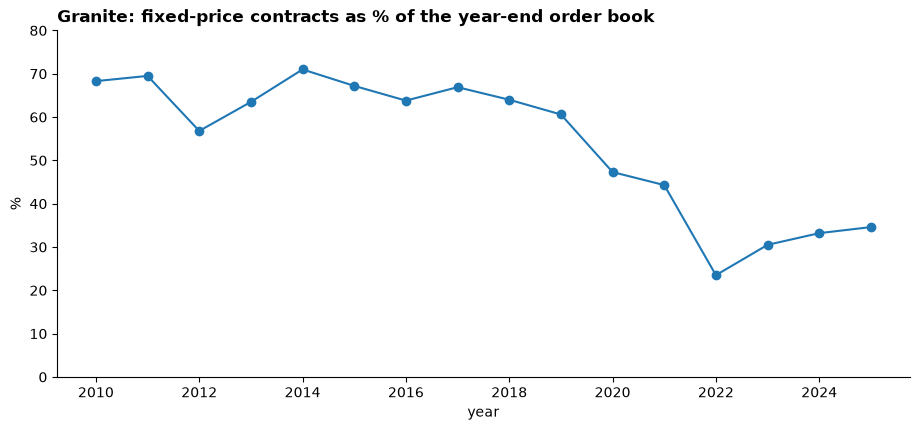

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
fixed_price_share_of_order_book,NaN,68.3,69.5,56.8,63.5,71.0,67.2,63.8,66.9,64.0,60.6,47.3,44.3,23.5,30.5,33.2,34.6


In [7]:
ax = granite.plot(x='year', y='fixed_price_share_of_order_book', marker='o', legend=False)
ax.set_ylim(0, 80)
ax.set_title('Granite: fixed-price contracts as % of the year-end order book', loc='left', fontweight='bold')
ax.set_ylabel('%')
plt.show()
granite[['year', 'fixed_price_share_of_order_book']].set_index('year').T

Between 2010 and 2019, 57% to 71% of the order book was fixed price. It dropped to 23.5% at the end of 2022 and has been around a third since. In 2021 the 10-K started calling it "unearned revenue" instead of "contract backlog", but it's the same thing: work won but not done yet.

### 2.2 Construction against materials

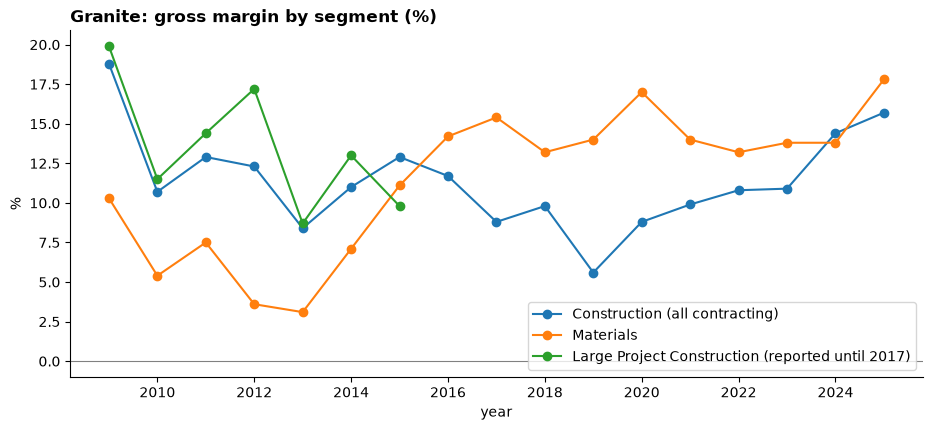

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
construction_margin,18.8,10.7,12.9,12.3,8.4,11.0,12.9,11.7,8.8,9.8,5.6,8.8,9.9,10.8,10.9,14.4,15.7
materials_margin,10.3,5.4,7.5,3.6,3.1,7.1,11.1,14.2,15.4,13.2,14.0,17.0,14.0,13.2,13.8,13.8,17.8
large_project_margin,19.9,11.5,14.4,17.2,8.7,13.0,9.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
ax = granite.plot(x='year', y=['construction_margin', 'materials_margin', 'large_project_margin'], marker='o')
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('Granite: gross margin by segment (%)', loc='left', fontweight='bold')
ax.set_ylabel('%')
ax.legend(['Construction (all contracting)', 'Materials', 'Large Project Construction (reported until 2017)'])
plt.show()
granite[['year', 'construction_margin', 'materials_margin', 'large_project_margin']].set_index('year').T

### 2.3 Fixed-price share against margin

The order book at the end of a year is mostly the next year's work, so I compare each year-end share with the following year's construction margin.

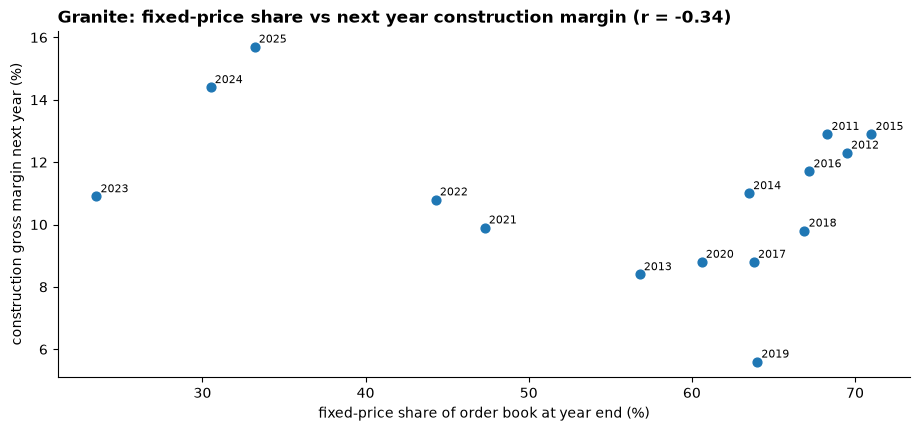

Correlation with next year margin: -0.34   same year: -0.28   years: 15


In [9]:
pairs = pd.DataFrame({
    'order_book_year': granite.year,
    'fixed_price_share': granite.fixed_price_share_of_order_book,
    'next_year_construction_margin': granite.construction_margin.shift(-1),
}).dropna()
r = pairs.fixed_price_share.corr(pairs.next_year_construction_margin)
same_year = granite.fixed_price_share_of_order_book.corr(granite.construction_margin)

ax = pairs.plot.scatter(x='fixed_price_share', y='next_year_construction_margin', s=40)
for p in pairs.itertuples():
    ax.annotate(str(p.order_book_year + 1), (p.fixed_price_share, p.next_year_construction_margin), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax.set_title(f'Granite: fixed-price share vs next year construction margin (r = {r:.2f})', loc='left', fontweight='bold')
ax.set_xlabel('fixed-price share of order book at year end (%)')
ax.set_ylabel('construction gross margin next year (%)')
plt.show()
print(f'Correlation with next year margin: {r:.2f}   same year: {same_year:.2f}   years: {len(pairs)}')

In [10]:
low = pairs[pairs.fixed_price_share < 50].next_year_construction_margin
high = pairs[pairs.fixed_price_share >= 50].next_year_construction_margin
pd.DataFrame({'years': [len(high), len(low)], 'average_next_year_margin': [round(high.mean(), 1), round(low.mean(), 1)]},
             index=['fixed price 50% or more', 'fixed price under 50%'])

,years,average_next_year_margin
fixed price 50% or more,10,10.2
fixed price under 50%,5,12.3


There's a link, but it's weak (r = -0.34 over 15 years). From 2009 to 2015 about two thirds of the work was fixed price and margins were still healthy, because costs came in at or under the estimates and net revisions were positive every year. Fixed prices only hurt once costs move after the price is agreed, which is what the next chart picks up.

### 2.4 Profit lost after the price was agreed

Granite lists the projects whose expected profit it revised during the year by more than a set amount. A downward revision means the costs came out higher than the estimate the price was based on. Up to 2015 the cut-off was $1.0M per project and from 2016 it's $5.0M, so the later years only count the bigger hits. I take each year from the latest filing that reports it, which picks up the 2019 restatement of 2017 and 2018.

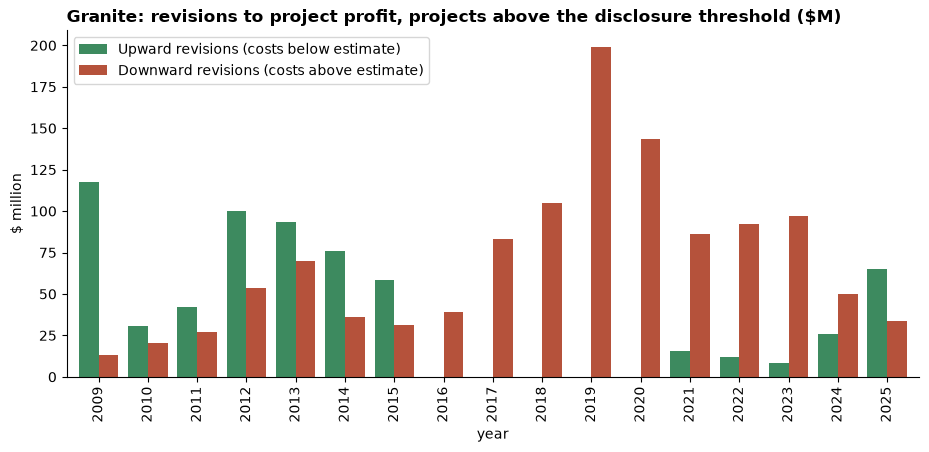

,upward_revisions,downward_revisions,net_revisions,downward_revisions_pct_of_construction,disclosure_threshold_musd
year,,,,,
2009,117.3,13.2,104.1,0.75,1.0
2010,30.6,20.7,9.9,1.36,1.0
2011,41.9,26.8,15.1,1.52,1.0
2012,100.1,53.6,46.5,2.90,1.0
2013,93.6,69.8,23.8,3.44,1.0
2014,76.0,36.4,39.6,1.81,1.0
2015,58.6,31.1,27.5,1.50,1.0
2016,0.0,39.4,-39.4,1.75,5.0
2017,0.0,83.4,-83.4,3.13,5.0


In [11]:
ax = granite.plot.bar(x='year', y=['upward_revisions', 'downward_revisions'], color=['#3d8a5f', '#b5523b'], width=0.8)
ax.set_title('Granite: revisions to project profit, projects above the disclosure threshold ($M)', loc='left', fontweight='bold')
ax.set_ylabel('$ million')
ax.legend(['Upward revisions (costs below estimate)', 'Downward revisions (costs above estimate)'])
plt.show()
granite[['year', 'upward_revisions', 'downward_revisions', 'net_revisions', 'downward_revisions_pct_of_construction',
         'disclosure_threshold_musd']].set_index('year')

### 2.5 Three periods

In [12]:
granite['period'] = pd.cut(granite.year, [2008, 2015, 2023, 2025], labels=['2009 to 2015', '2016 to 2023', '2024 to 2025'])
periods = granite.groupby('period', observed=True).agg(
    fixed_price_share=('fixed_price_share_of_order_book', 'mean'),
    construction_margin=('construction_margin', 'mean'),
    materials_margin=('materials_margin', 'mean'),
    net_revisions_musd=('net_revisions', 'sum'),
).round(1)
periods

,fixed_price_share,construction_margin,materials_margin,net_revisions_musd
period,,,,
2009 to 2015,66.0,12.4,6.9,266.5
2016 to 2023,50.1,9.5,14.4,-809.4
2024 to 2025,33.9,15.0,15.8,6.8


### 2.6 How Granite's clients changed the way they buy

From the 2020 and 2021 10-K filings, and the list of contract types in the 2025 one:

In [13]:
for year in (2020, 2021):
    found = re.search(r'[^.]*best-value or alternative delivery procurement[^.]*\.', quotes[year])
    print(year, found.group(0).strip(), '\n')
print(2025, re.search(r'[^.]*procurement methods that include[^;]*', quotes[2025]).group(0).strip())

2020 This year we are seeing increased interest in best-value or alternative delivery procurement work by the state Department of Transportations, such as California and Utah, along with other state agencies. 

2021 During 2021, we saw increased interest in best-value or alternative delivery procurement work by state departments of transportation, such as California and Utah, along with other state agencies. 



2025 Diversification: To mitigate the risks inherent in the construction business as the result of general economic factors, we pursue projects: (1) in both the public and private sectors; (2) in diverse end markets such as federal, rail, power and water; (3) for a wide range of clients from the federal government to small municipalities and from large corporations to small private customers; (4) in diverse geographic markets; (5) with procurement methods that include construction management/general contractor (“CM/GC”), construction management at-risk (“CMAR”), progressive design-build, bid-build and design-build


With CM/GC and CMAR the client picks a contractor early, usually on qualifications and interviews, and agrees the price with them as the design develops instead of taking the lowest sealed bid. To win work that way you need to know the client's people before the tender comes out. Granite's margins recovered over the same years.

## 3. Costs in Mauritius

Statistics Mauritius publishes a monthly Construction Price Index, split into labour, materials, plant hire and transport (first quarter 2018 = 100). `fetch_copi` in `escalation_check.py` downloads every quarterly release and stitches them together.

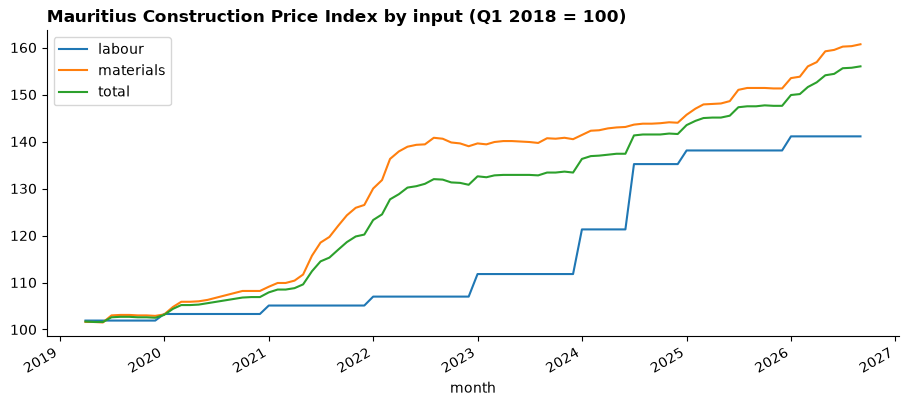

,labour index change in the month (%)
month,
2020-01-01,1.4
2021-01-01,1.7
2022-01-01,1.8
2023-01-01,4.5
2024-01-01,8.5
2024-07-01,11.5
2025-01-01,2.1
2026-01-01,2.2


In [14]:
from escalation_check import fetch_copi

copi = fetch_copi()
ax = copi[['labour', 'materials', 'total']].plot()
ax.set_title('Mauritius Construction Price Index by input (Q1 2018 = 100)', loc='left', fontweight='bold')
plt.show()
jumps = (copi.labour.pct_change() * 100).round(1)
jumps[jumps.abs() > 0.05].to_frame('labour index change in the month (%)')

In [15]:
yearly = copi.groupby(copi.index.year).mean()
yearly_change = (yearly.pct_change() * 100).round(1)[['labour', 'materials', 'total']]
yearly_change.columns = ['labour_change_pct', 'materials_change_pct', 'total_change_pct']
yearly_change

,labour_change_pct,materials_change_pct,total_change_pct
month,,,
2019,NaN,NaN,NaN
2020,1.4,3.7,3.1
2021,1.7,10.0,7.5
2022,1.8,17.8,14.1
2023,4.5,1.7,2.8
2024,14.7,2.2,4.7
2025,7.7,4.4,4.9
2026,2.2,5.6,4.9


The labour index barely moved until 2022, then rose 4.5% in 2023, 14.7% in 2024 and 7.7% in 2025 on yearly averages, most of it in two steps: 8.5% in January 2024 and 11.5% in July 2024. Materials went up earlier, 10% in 2021 and 17.8% in 2022. The index is based on building a single-storey house, so for road and civil work it's an approximation, but it's the official figure and it comes out every month.

## 4. What I take from this

Granite's figures say fixed prices on their own are not what squeezes a contractor. With two thirds of its work on fixed prices in 2009 to 2015 it still averaged 12.4% on construction. The trouble starts when costs overrun the bids. Between 2016 and 2023 that cost Granite $809M in net revisions, and construction made 9.5% while materials, which could change its prices, made 14.4%. The construction margin came back (15.0% in 2024 and 2025) as clients moved towards picking their contractor early and agreeing the price with them, instead of taking the lowest bid.

Mauritian contractors have just been through their own version of this. On a fixed-price contract signed before 2024, the labour part of the official cost index went up 8.5% and then 11.5% within seven months, after the materials rises of 2021 and 2022, and none of it could be billed on.

That suggests one quick fix and one slow one. The quick one is to stop absorbing cost rises on the bids going out now, by pricing them in or tying the price to the official index. `escalation_check.py` does that. For each bid it estimates the margin lost at the current cost trend, the price that would keep the target margin, and a price adjustment formula to put in the contract instead. On the example road works bid in this folder, a 5% target margin falls to 0.2% if the price stays fixed.

But a client running a lowest-price tender won't accept a higher price or an escalation clause when the next bidder doesn't ask for one, so the quick fix only works with clients who want you in particular. Getting more of those clients is the slow fix, which is where Granite's recovery points, and most of it is account managers knowing the people who decide and keeping in touch with them. `kdm_touchpoints.py` turns what they pick up in meetings (a pet's birthday, a half marathon, a tender date, the anniversary of a handover) into a calendar of reminders with a draft message for each, plus a short brief before a meeting. It never suggests gifts for public-sector contacts, and it refuses notes that have no source or touch on sensitive topics.